In [Chapter 11](11_ARMA.ipynb) we made the monthly temperatures stationary by hand with a seasonal difference, fitted ARMA models, and put the seasonality back by hand. Two problems were left. The bookkeeping of differencing and undoing it is error-prone. And the seasonal difference created a correlation at lag 12 that no non-seasonal ARMA model could remove.

This chapter solves both. The **ARIMA** model moves the differencing inside the model, so that `statsmodels` forecasts on the original scale. The **seasonal ARIMA (SARIMA)** model adds seasonal AR and MA terms, which act at lags $s, 2s, 3s, \dots$. Finally, we turn to the hardest practical question: out of the many possible orders $(p, d, q) \times (P, D, Q)_s$, which model do we choose?

# Learning objectives

By the end of this lecture you should be able to

1. write down an **ARIMA($p, d, q$)** model, explain the role of $d$, and recognize the random walk and simple exponential smoothing as special cases;
2. explain what a **constant** means in a differenced model, and recognize **over-differencing**;
3. write down a **SARIMA**$(p, d, q) \times (P, D, Q)_s$ model and choose $s$, $D$, $P$ and $Q$ from the correlograms of the seasonally differenced series;
4. fit, check and forecast a SARIMA model with `statsmodels`;
5. select a model by **grid search**, using EDA to restrict the candidates, knowing which comparisons AIC and BIC allow, and evaluate the winners on a test set against simple benchmarks.

# Setup

Modules and functions used in this lecture.

| Module | Used for |
|---|---|
| `numpy` | `random.default_rng`, `diff`, `cumsum` |
| `pandas` | `read_csv`, `groupby`, `diff`, `DataFrame` |
| `matplotlib.pyplot` | `subplots`, `plot`, `bar`, `vlines`, `fill_between` |
| `itertools` | `product` -- all combinations of the candidate orders |
| `time` | `perf_counter` -- timing the grid search |
| `statsmodels.tsa.arima_process` | `ArmaProcess` |
| `statsmodels.tsa.stattools` | `adfuller`, **`acf`**, **`pacf`** -- the correlations as numbers, with confidence intervals |
| `statsmodels.graphics.tsaplots` | `plot_acf`, `plot_pacf` |
| `statsmodels.stats.diagnostic` | `acorr_ljungbox` (Chapter 7) |
| `statsmodels.tsa.holtwinters` | `ExponentialSmoothing` (Chapter 6) |
| `statsmodels.tsa.arima.model` | **`ARIMA`** -- ARIMA($p, d, q$) models |
| `statsmodels.tsa.statespace.sarimax` | **`SARIMAX`** -- seasonal ARIMA models |

In [1]:
import time
import warnings
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.arima_process import ArmaProcess
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Expected noise we do not want in the output:
#  - ARIMA/SARIMAX warn when the optimizer stops before full convergence, and when
#    they replace unusable starting values by zeros;
#  - statsmodels 0.15 announces a future change to the return type of adfuller.
from statsmodels.tools.sm_exceptions import ConvergenceWarning, EstimationWarning
warnings.simplefilter("ignore", ConvergenceWarning)
warnings.simplefilter("ignore", EstimationWarning)
warnings.simplefilter("ignore", FutureWarning)

rng = np.random.default_rng(8990)     # reproducibility: the same seed as Chapter 11

Self-defined functions carried over from earlier chapters: the run-sequence plot (Chapter 4), the MSE (Chapter 6), the correlogram helpers of Chapter 9, `score_table` from Chapter 10, and `forecast_with_interval` from Chapter 11.

In [2]:
def run_sequence_plot(y, x=None, title="", xlabel="time", ylabel="value",
                      ax=None, figsize=(9, 3), color="blue", **kwargs):
    "Plot a series against time and return the axes."
    if ax is None:
        _, ax = plt.subplots(figsize=figsize)
    if x is None:
        x = getattr(y, "index", np.arange(len(y)))
    ax.plot(x, y, color=color, lw=1, **kwargs)
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    ax.grid(alpha=0.3)
    return ax


def mse(observations, estimates):
    "Mean squared error between two equal-length sequences."
    observations = np.asarray(observations, dtype=float)
    estimates = np.asarray(estimates, dtype=float)
    if observations.shape != estimates.shape:
        raise ValueError(f"shape mismatch: {observations.shape} vs {estimates.shape}")
    return np.mean((observations - estimates) ** 2)


def theory_marks(ax, values, label="theory"):
    "Mark theoretical correlations (lag 0, 1, 2, ...) on a correlogram."
    ax.plot(np.arange(len(values)), values, "_", color="red", ms=14, mew=2, label=label)
    ax.legend(loc="upper right", fontsize=8)


def correlograms(x, lags=20, process=None, title=""):
    "ACF and PACF side by side, optionally with the theoretical values of an ArmaProcess."
    fig, axes = plt.subplots(1, 2, figsize=(12, 3))
    plot_acf(x, lags=lags, ax=axes[0], title=f"ACF {title}")
    plot_pacf(x, lags=lags, ax=axes[1], title=f"PACF {title}")
    if process is not None:
        theory_marks(axes[0], process.acf(lags + 1))
        theory_marks(axes[1], process.pacf(lags + 1))
    for ax in axes:
        ax.set_xlabel("lag k")
        ax.grid(alpha=0.3)
    fig.tight_layout()
    return axes


def score_table(test, forecasts, h_short=3):
    "Test-set MSE of several forecasts, over all steps and over the first h_short steps."
    print(f"{'':34s}{f'MSE, all {len(test)} steps':>20s}{f'MSE, first {h_short} steps':>22s}")
    for name, preds in forecasts.items():
        preds = np.asarray(preds)
        print(f"{name:34s}{mse(test, preds):20.2f}{mse(test[:h_short], preds[:h_short]):22.2f}")


def forecast_with_interval(ax, fit, steps, x, color="red", label="forecast"):
    "Draw the forecast of a fitted model and its 95% prediction interval; return the forecast."
    fc = fit.get_forecast(steps)
    ci = np.asarray(fc.conf_int(alpha=0.05))
    ax.plot(x, np.asarray(fc.predicted_mean), color=color, ls="--", lw=1.5, label=label)
    ax.fill_between(x, ci[:, 0], ci[:, 1], color=color, alpha=0.15)
    return np.asarray(fc.predicted_mean)

One new one: `mape`, the mean absolute percentage error of Chapter 1, used in the grid search.

In [3]:
def mape(observations, estimates):
    "Mean absolute percentage error, in percent."
    observations = np.asarray(observations, dtype=float)
    estimates = np.asarray(estimates, dtype=float)
    return 100 * np.mean(np.abs((observations - estimates) / observations))

# The ARIMA model

ARIMA stands for **AutoRegressive Integrated Moving Average**. An ARIMA($p, d, q$) model has three components: an AR model of order $p$, an **integrated** component of order $d$, where $d$ is the number of times the data are differenced, and an MA model of order $q$. All three orders are nonnegative integers. With the backshift operator,

$$\phi(B)\,(1 - B)^d\, x_t = c + \theta(B)\,\varepsilon_t .$$

In words: difference the series $d$ times, $w_t = (1 - B)^d x_t$, and model $w_t$ as an ARMA($p, q$):

- $d = 0$: no differencing, $w_t = x_t$; ARIMA($p$, 0, $q$) is the ARMA($p, q$) model of Chapter 11;
- $d = 1$: difference once, $w_t = x_t - x_{t-1}$;
- $d = 2$: difference twice, $w_t = (x_t - x_{t-1}) - (x_{t-1} - x_{t-2})$.

As we saw in Chapter 5, differencing a nonstationary series one or more times can make it stationary. That is the role of the integrated component. An ARMA model is suitable for *stationary* series, whose mean and variance do not change over time; an ARIMA model handles *nonstationary* ones by differencing them first, internally. To forecast, it forecasts $w_t$ and integrates back, the cumulative sums of Chapter 10, on its own.

**Why "integrated"?** The factor $(1 - B)^d$ is an AR polynomial with $d$ roots exactly at $z = 1$: **unit roots**, the property that the ADF test of Chapter 5 looks for. A series that becomes stationary after $d$ differences is called *integrated of order $d$*.

Several models we have met are special cases.

| ARIMA | Model |
|---|---|
| (0, 0, 0) with a constant | white noise around a mean |
| (0, 1, 0) | random walk (Chapter 4); with a constant, a random walk with drift |
| (0, 1, 1) | simple exponential smoothing (Chapter 6), with $\alpha = 1 + \theta_1$ (shown at the end of this section) |
| ($p$, 0, $q$) | ARMA($p, q$) (Chapter 11) |

## Example: ARMA vs ARIMA

We reuse the ARMA(1,1) process of Chapter 11, $x_t = 0.7\,x_{t-1} + \varepsilon_t + 0.7\,\varepsilon_{t-1}$: with the same seed, these are the same 250 points. Adding a quadratic trend $0.05\,t^2$ gives a nonstationary series that needs **two** differences: the first difference of $0.05\,t^2$ is a linear trend, the second a constant.

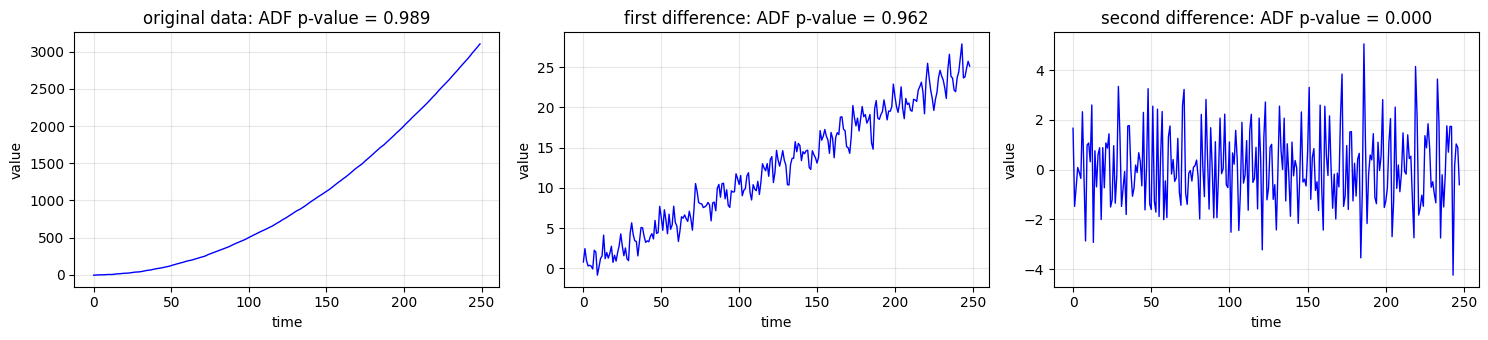

In [4]:
n = 250
arma11 = ArmaProcess(ar=np.array([1.0, -0.7]), ma=np.array([1.0, 0.7]))     # ar signs flipped
arma_data = arma11.generate_sample(nsample=n, scale=1, burnin=1000, distrvs=rng.standard_normal)

t = np.arange(n)
non_stationary_data = 0.05 * t ** 2 + arma_data          # quadratic trend

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, (name, y) in zip(axes, [("original data", non_stationary_data),
                                ("first difference", np.diff(non_stationary_data)),
                                ("second difference", np.diff(non_stationary_data, n=2))]):
    run_sequence_plot(y, title=f"{name}: ADF p-value = {adfuller(y)[1]:.3f}", ax=ax)
plt.tight_layout(); plt.show()

The ADF test fails to reject a unit root for the original series and for its first difference, and rejects it for the second difference. So $d = 2$.

We hold out the last $H = 20$ points and compare two models on each series, starting with the **stationary** ARMA data: ARMA(1,1), i.e., ARIMA(1, 0, 1), against ARIMA(1, 1, 1), which differences once before fitting.

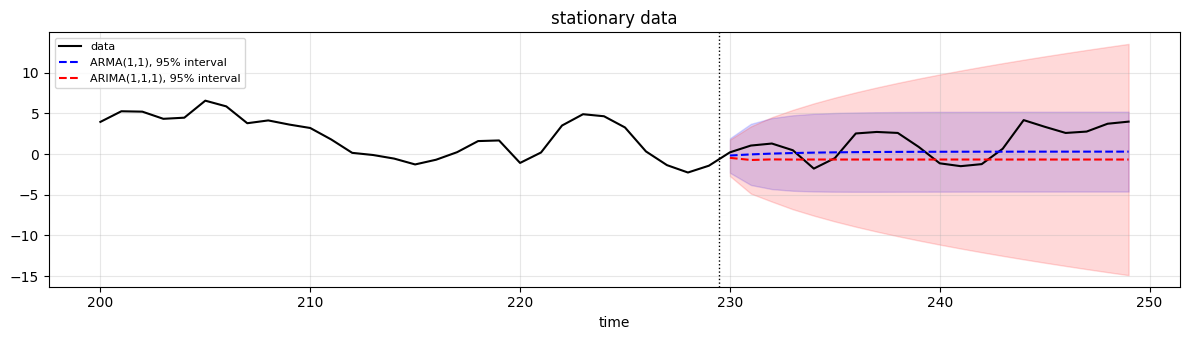

                                     MSE, all 20 steps    MSE, first 3 steps
ARMA(1,1)                                         4.65                  0.95
ARIMA(1,1,1)                                      7.53                  2.46
ARMA(1,1): width of the 95% interval at h = 20: 9.8
ARIMA(1,1,1): width of the 95% interval at h = 20: 28.4
ARMA(1,1): {'const': 0.297, 'ar.L1': 0.712, 'ma.L1': 0.752, 'sigma2': 1.168}
ARIMA(1,1,1): {'ar.L1': -0.273, 'ma.L1': 0.825, 'sigma2': 1.301}


In [5]:
H = 20
t_test = t[-H:]


def compare_on(y, fits, title, ylim=None, last=50):
    "Plot the last points of y and the H-step forecasts of several fitted models; print MSE and interval width."
    _, ax = plt.subplots(figsize=(12, 3.5))
    ax.plot(t[-last:], y[-last:], color="black", lw=1.5, label="data")
    preds = {}
    for (name, fit), color in zip(fits.items(), ["blue", "red", "green", "purple"]):
        preds[name] = forecast_with_interval(ax, fit, H, t_test, color=color, label=f"{name}, 95% interval")
    ax.axvline(t_test[0] - 0.5, color="black", ls=":", lw=1)
    ax.set(title=title, xlabel="time"); ax.grid(alpha=0.3)
    if ylim is not None:
        ax.set_ylim(ylim)
    ax.legend(loc="upper left", fontsize=8)
    plt.tight_layout(); plt.show()
    score_table(y[-H:], preds)
    for name, fit in fits.items():
        lower, upper = np.asarray(fit.get_forecast(H).conf_int(alpha=0.05))[-1]
        print(f"{name}: width of the 95% interval at h = {H}: {upper - lower:.1f}")


stationary_fits = {
    "ARMA(1,1)":    ARIMA(arma_data[:-H], order=(1, 0, 1)).fit(),
    "ARIMA(1,1,1)": ARIMA(arma_data[:-H], order=(1, 1, 1)).fit(),
}
compare_on(arma_data, stationary_fits, "stationary data")
for name, fit in stationary_fits.items():
    print(f"{name}: {dict(zip(fit.param_names, fit.params.round(3).tolist()))}")

- **ARMA(1,1)** recovers the true coefficients well ($\hat\phi_1 \approx 0.71$, $\hat\theta_1 \approx 0.75$). Its forecast reverts to the mean, and its prediction interval stops widening after a few steps (width 9.8 at $h = 20$), as for every stationary model (Chapter 10).
- **ARIMA(1,1,1)** differences data that did not need it. Its forecast stays close to the last value and does not revert to the mean, and its interval keeps widening (28.4 at $h = 20$): after one difference the model treats the level as a random walk, so it believes the series can drift anywhere. Its MSE is larger.

Differencing a series that is already stationary is called **over-differencing**. It throws away the information that the series returns to its mean.

Now the **nonstationary** series, with ARMA(1,1) against ARIMA(1, 2, 1).

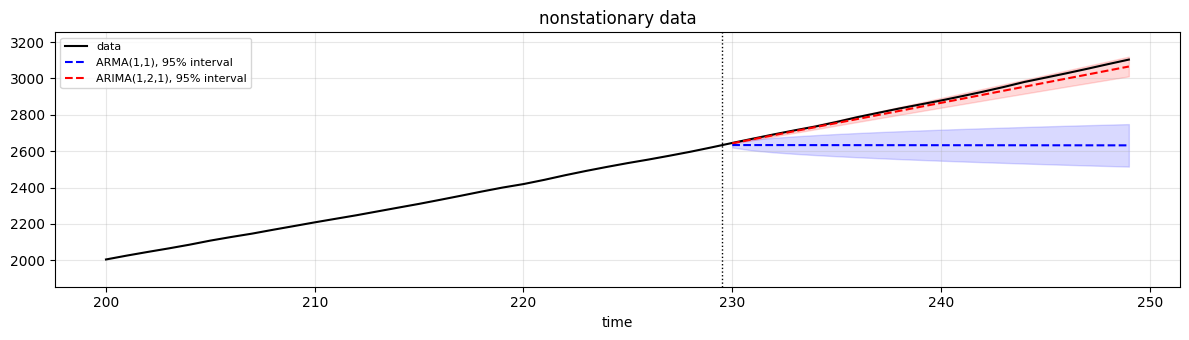

                                     MSE, all 20 steps    MSE, first 3 steps
ARMA(1,1)                                     76191.37               1623.66
ARIMA(1,2,1)                                    388.64                 11.24
ARMA(1,1): width of the 95% interval at h = 20: 233.9
ARIMA(1,2,1): width of the 95% interval at h = 20: 108.5
ARMA(1,1): {'const': 877.242, 'ar.L1': 1.0, 'ma.L1': 0.973, 'sigma2': 47.511}
ARIMA(1,2,1): {'ar.L1': 0.363, 'ma.L1': -0.814, 'sigma2': 1.895}


In [6]:
nonstationary_fits = {
    "ARMA(1,1)":    ARIMA(non_stationary_data[:-H], order=(1, 0, 1)).fit(),
    "ARIMA(1,2,1)": ARIMA(non_stationary_data[:-H], order=(1, 2, 1)).fit(),
}
y_range = (non_stationary_data[-50:].min() - 150, non_stationary_data[-50:].max() + 150)
compare_on(non_stationary_data, nonstationary_fits, "nonstationary data", ylim=y_range)
for name, fit in nonstationary_fits.items():
    print(f"{name}: {dict(zip(fit.param_names, fit.params.round(3).tolist()))}")

- **ARMA(1,1)** cannot describe a trend. The optimizer pushes $\hat\phi_1$ to 1.000, the edge of stationarity: the model behaves like a random walk, and its forecast stays flat at the last value, missing the continuing rise completely.
- **ARIMA(1,2,1)** follows the trend. Its MSE is still large, though, because its forecast continues the trend as a **straight line**, while the data keep curving upwards.

### The constant in a differenced model

The reason is the constant $c$. By default, `ARIMA` leaves it out when $d \ge 1$. In a differenced model, a constant means much more than a mean level:

- with $d = 1$, a constant $c$ in $w_t = x_t - x_{t-1}$ means that $x_t$ rises by $c$ per step on average: a linear trend, or **drift**;
- with $d = 2$, a constant $c$ in the second difference means a **quadratic** trend $\tfrac{c}{2}\,t^2$.

Our trend $0.05\,t^2$ has second difference $0.1$, which the model above forces to zero. `statsmodels` specifies trend terms on the *undifferenced* series: `trend="t"` for a drift when $d = 1$, and `trend=[0, 0, 1]` (only a $t^2$ term) when $d = 2$. We also fit the model we actually simulated: a **deterministic** quadratic trend with ARMA(1,1) errors, `ARIMA(order=(1, 0, 1), trend=[1, 1, 1])`, a regression on $1, t, t^2$ whose errors are ARMA (*dynamic regression*, Chapter 9).

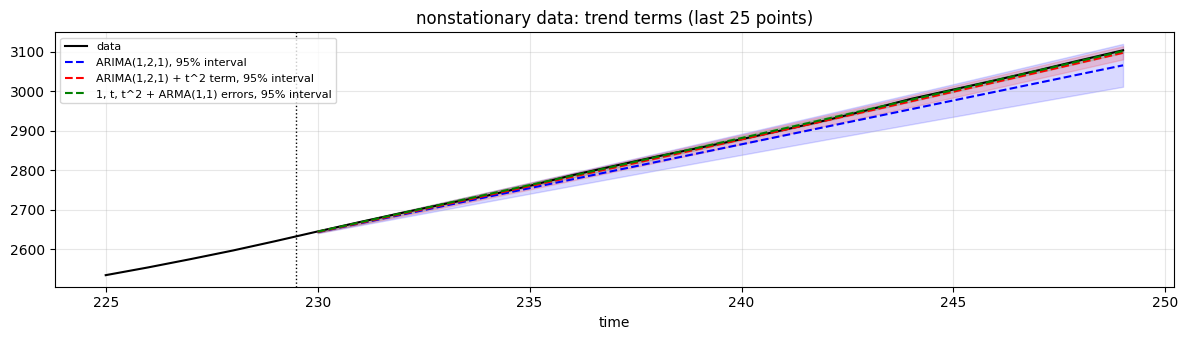

                                     MSE, all 20 steps    MSE, first 3 steps
ARIMA(1,2,1)                                    388.64                 11.24
ARIMA(1,2,1) + t^2 term                          13.86                  4.35
1, t, t^2 + ARMA(1,1) errors                      3.12                  0.52
ARIMA(1,2,1): width of the 95% interval at h = 20: 108.5
ARIMA(1,2,1) + t^2 term: width of the 95% interval at h = 20: 33.3
1, t, t^2 + ARMA(1,1) errors: width of the 95% interval at h = 20: 9.6
ARIMA(1,2,1) + t^2 term: {'x1': 0.05, 'ar.L1': 0.332, 'ma.L1': -1.0, 'sigma2': 1.549}
1, t, t^2 + ARMA(1,1) errors: {'const': 0.368, 'x1': -0.112, 'x2': 0.05, 'ar.L1': 0.737, 'ma.L1': 0.537, 'sigma2': 1.312}


In [7]:
trend_fits = {
    "ARIMA(1,2,1)":                 nonstationary_fits["ARIMA(1,2,1)"],
    "ARIMA(1,2,1) + t^2 term":      ARIMA(non_stationary_data[:-H], order=(1, 2, 1), trend=[0, 0, 1]).fit(),
    "1, t, t^2 + ARMA(1,1) errors": ARIMA(non_stationary_data[:-H], order=(1, 0, 1), trend=[1, 1, 1]).fit(),
}
compare_on(non_stationary_data, trend_fits, "nonstationary data: trend terms (last 25 points)", last=25)
for name, fit in list(trend_fits.items())[1:]:
    print(f"{name}: {dict(zip(fit.param_names, fit.params.round(3).tolist()))}")

- With the $t^2$ term the ARIMA forecast curves with the data, and the MSE drops by a factor of about 30. The estimated coefficient of $t^2$ (`statsmodels` labels the trend terms `x1`, `x2`, ...) is 0.05, the true value.
- But look at $\hat\theta_1 = -1.000$. The MA polynomial $(1 - B)$ cancels one of the two differences. **An MA unit root is the signature of over-differencing.** The data did not need two differences: the trend is deterministic, and differencing a stationary ARMA component creates a non-invertible MA part.
- The deterministic-trend model recovers the simulated coefficients ($0.05\,t^2$ as `x2`, $\hat\phi_1 \approx 0.74$, $\hat\theta_1 \approx 0.54$), has the lowest MSE, and has much narrower intervals (9.6 at $h = 20$, against 33.3 with the $t^2$ term and 108.5 without).

> **Deterministic or stochastic trend?** Differencing assumes a *stochastic* trend, one that is driven by accumulated shocks and can change direction; the prediction intervals grow without bound. A regression on time assumes a *deterministic* trend that continues exactly; its intervals stay narrow. On real data we rarely know which is true, and over long horizons the deterministic assumption is risky: extrapolating a quadratic for decades is rarely wise. Differencing is the more cautious default.

### ARIMA(0,1,1) and simple exponential smoothing

The table of special cases claimed that ARIMA(0,1,1) is simple exponential smoothing. The model $x_t = x_{t-1} + \varepsilon_t + \theta_1\varepsilon_{t-1}$ forecasts $\hat x_{T+1} = x_T + \theta_1\,\varepsilon_T$, and with $\varepsilon_T = x_T - \hat x_T$ this is

$$\hat x_{T+1} = (1 + \theta_1)\,x_T - \theta_1\,\hat x_T ,$$

the SES recursion $\hat x_{T+1} = \alpha\,x_T + (1 - \alpha)\,\hat x_T$ of Chapter 6 with $\alpha = 1 + \theta_1$. We check it on a random walk observed with noise, the kind of series SES is made for.

In [8]:
rw_noise = np.cumsum(rng.standard_normal(300)) + 1.5 * rng.standard_normal(300)

ses = ExponentialSmoothing(rw_noise).fit()
arima011 = ARIMA(rw_noise, order=(0, 1, 1)).fit()

print(f"SES:          alpha        = {ses.params['smoothing_level']:.3f},  next forecast = {ses.forecast(1)[0]:.3f}")
print(f"ARIMA(0,1,1): 1 + theta_1  = {1 + arima011.params[0]:.3f},  next forecast = {arima011.forecast(1)[0]:.3f}")

SES:          alpha        = 0.479,  next forecast = 43.640
ARIMA(0,1,1): 1 + theta_1  = 0.481,  next forecast = 43.635


The two agree to two decimals. The small differences come from estimation: SES minimizes the sum of squared one-step errors, ARIMA maximizes the likelihood. One consequence: everything we said about SES forecasts in Chapter 6 applies to ARIMA(0,1,1), and ARIMA additionally provides prediction intervals from the model.

---

# The SARIMA model

To apply ARMA and ARIMA to the temperatures in Chapter 11, we had to remove the seasonal component first and put it back after forecasting. It would be more convenient to work directly on the seasonal data. **SARIMA** extends ARIMA with seasonal terms. The model is written SARIMA$(p, d, q) \times (P, D, Q)_s$, with

the regular ARIMA components $(p, d, q)$, and the seasonal components $(P, D, Q, s)$, where $P$ is the seasonal autoregressive order, $D$ the seasonal differencing order, $Q$ the seasonal moving-average order, and $s$ the number of time steps in one seasonal period.

In backshift notation,

$$\Phi(B^s)\,\phi(B)\,(1 - B^s)^D (1 - B)^d\, x_t = c + \Theta(B^s)\,\theta(B)\,\varepsilon_t ,$$

where $\Phi(B^s) = 1 - \Phi_1 B^s - \dots - \Phi_P B^{Ps}$ and $\Theta(B^s) = 1 + \Theta_1 B^s + \dots + \Theta_Q B^{Qs}$ are AR and MA polynomials in $B^s$ instead of $B$. They link $x_t$ to $x_{t-s}, x_{t-2s}, \dots$ and to the shocks $\varepsilon_{t-s}, \varepsilon_{t-2s}, \dots$: the same month in earlier years. $(1 - B^s)^D$ is the seasonal difference of Chapter 5, applied $D$ times.

The seasonal and non-seasonal polynomials **multiply**. For example, SARIMA$(0,0,1)\times(0,0,1)_{12}$ is

$$x_t = (1 + \theta_1 B)(1 + \Theta_1 B^{12})\,\varepsilon_t = \varepsilon_t + \theta_1\varepsilon_{t-1} + \Theta_1\varepsilon_{t-12} + \theta_1\Theta_1\,\varepsilon_{t-13},$$

with an interaction term at lag 13. Two coefficients describe dependence at lags 1, 12 and 13.

In `statsmodels`, `SARIMAX(x, order=(p, d, q), seasonal_order=(P, D, Q, s))` fits this model (the X stands for optional exogenous regressors). `ARIMA(x, order=..., seasonal_order=...)`, which we previewed in Chapter 10, is equivalent.

## Choosing $s$, $D$, $P$ and $Q$

- **$s$** is the main seasonality in the data. We already know how to find it: the ACF, the subseries plot and the FFT (Chapter 11).
- **$D$** is the number of seasonal differences needed to make the series (seasonally) stationary. It is almost always 0 or 1, and is often settled by trial and error or by examining the seasonally differenced data.
- **$P$ and $Q$** come from the PACF and ACF at the seasonal lags $s, 2s, 3s, \dots$ of the (seasonally differenced) series. There should be a spike at lag $s$, and possibly at its multiples. The rules of Chapters 9 and 10 apply, at the seasonal lags:
  - $Q$: look at the **ACF** at the seasonal lags. If it cuts off sharply, say after lag $s$ only, that suggests the seasonal MA order ($Q = 1$), and the PACF should decay at $s, 2s, 3s$.
  - $P$: look at the **PACF** at the seasonal lags. A sharp cut-off suggests the seasonal AR order, and the ACF should decay at $s, 2s, 3s$.

> **Tip.** Before choosing $P$ and $Q$, make sure the series is seasonally stationary, applying a seasonal difference ($D = 1$) if needed. Then read the seasonal lags only; the short lags tell you $p$ and $q$.

## SARIMA on the monthly temperatures

We load the temperatures and use the same split as in Chapter 11: train on 1907-1969, test on 1970-1972.

In [9]:
temp = pd.read_csv("data/arima_temp.csv", skipfooter=2, header=0, index_col=0,
                   names=["month", "temp"], engine="python")
temp.index = pd.to_datetime(temp.index)
temp = temp["temp"].asfreq("MS")

temp_train = temp[:"1969-12-01"]
temp_test = temp["1970-01-01":]
print(f"train: {temp_train.index[0]:%b %Y} - {temp_train.index[-1]:%b %Y} ({len(temp_train)} months),  "
      f"test: {temp_test.index[0]:%b %Y} - {temp_test.index[-1]:%b %Y} ({len(temp_test)} months)")

train: Jan 1907 - Dec 1969 (756 months),  test: Jan 1970 - Dec 1972 (36 months)


$s = 12$, and a seasonal difference ($D = 1$) removes the seasonal pattern (Chapter 11). We look at the correlograms of the seasonally differenced training data over five seasonal cycles.

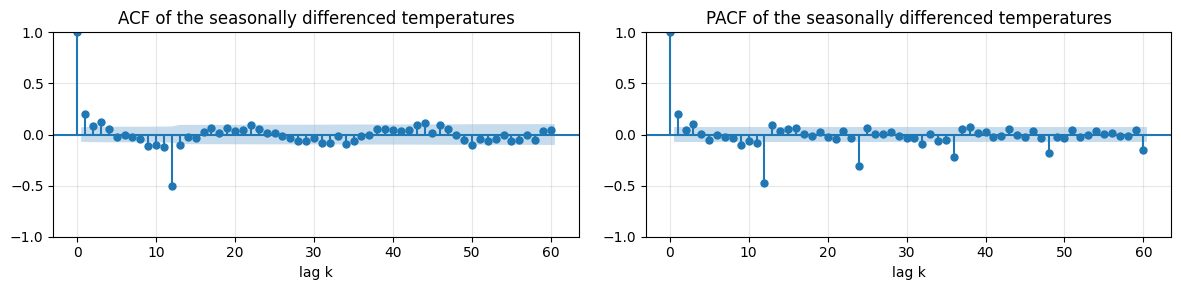

ACF  at lags 12, 24, ..., 60: [-0.5   0.01 -0.01 -0.01  0.04]
PACF at lags 12, 24, ..., 60: [-0.48 -0.32 -0.24 -0.21 -0.18]


In [10]:
train_d12 = temp_train.diff(12).iloc[12:]

correlograms(train_d12, lags=60, title="of the seasonally differenced temperatures")
plt.show()

r, ph = acf(train_d12, nlags=60), pacf(train_d12, nlags=60)
seasonal_lags = [12, 24, 36, 48, 60]
print("ACF  at lags 12, 24, ..., 60:", r[seasonal_lags].round(2))
print("PACF at lags 12, 24, ..., 60:", ph[seasonal_lags].round(2))

At the seasonal lags:

- the **ACF** has a single spike at lag 12 and nothing at 24, 36, 48 or 60: it cuts off after one seasonal lag, so $Q = 1$;
- the **PACF** decays at 12, 24, 36, 48: the MA signature, so $P = 0$.

This is the seasonal MA(1) we predicted in Chapter 11: a seasonal difference of a series with a stable seasonal pattern creates an MA term at lag 12 with a coefficient close to $-1$. For the short lags we take the simplest candidate of Chapter 11, $p = q = 1$, and no further differencing ($d = 0$), since the seasonally differenced series is already stationary. Our model is **SARIMA$(1, 0, 1) \times (0, 1, 1)_{12}$**.

In [11]:
sarima_fit = SARIMAX(temp_train, order=(1, 0, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
print(sarima_fit.summary())

                                     SARIMAX Results                                      
Dep. Variable:                               temp   No. Observations:                  756
Model:             SARIMAX(1, 0, 1)x(0, 1, 1, 12)   Log Likelihood               -2038.550
Date:                            Mon, 19 Oct 2026   AIC                           4085.100
Time:                                    08:32:56   BIC                           4103.548
Sample:                                01-01-1907   HQIC                          4092.211
                                     - 12-01-1969                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.5557      0.157      3.540      0.000       0.248       0.863
ma.L1         -0.3930      0.174   

All three coefficients are significant at the 5% level.

- The non-seasonal part, $\hat\phi_1 \approx 0.55$ and $\hat\theta_1 \approx -0.39$, is almost identical to the ARMA(1,1) we fitted to the anomalies in Chapter 11 (0.56 and $-0.39$).
- The seasonal MA coefficient is $\hat\Theta_1 \approx -0.98$. The factor $(1 - 0.98\,B^{12})$ on the right almost **cancels** the seasonal difference $(1 - B^{12})$ on the left. With $\Theta_1 = -1$ exactly, the model would be "a fixed seasonal pattern plus ARMA(1,1) noise", which is the monthly-means route of Chapter 11. The data are telling us that the seasonality is (nearly) **deterministic**: the same pattern every year.
- $\hat\sigma^2 \approx 13.3$ is about the variance of the anomalies' ARMA(1,1) residuals (12.9), half the 24-27 of the ARMA models on the seasonally differenced series in Chapter 11. The seasonal MA term has removed the noise that the seasonal difference had added.

Next, the residual checks. With $D = 1$ the first 12 residuals are dominated by the initialization of the model (it has not yet seen a full year), so we skip them, as `plot_diagnostics` does. The number to skip is stored in `loglikelihood_burn`.

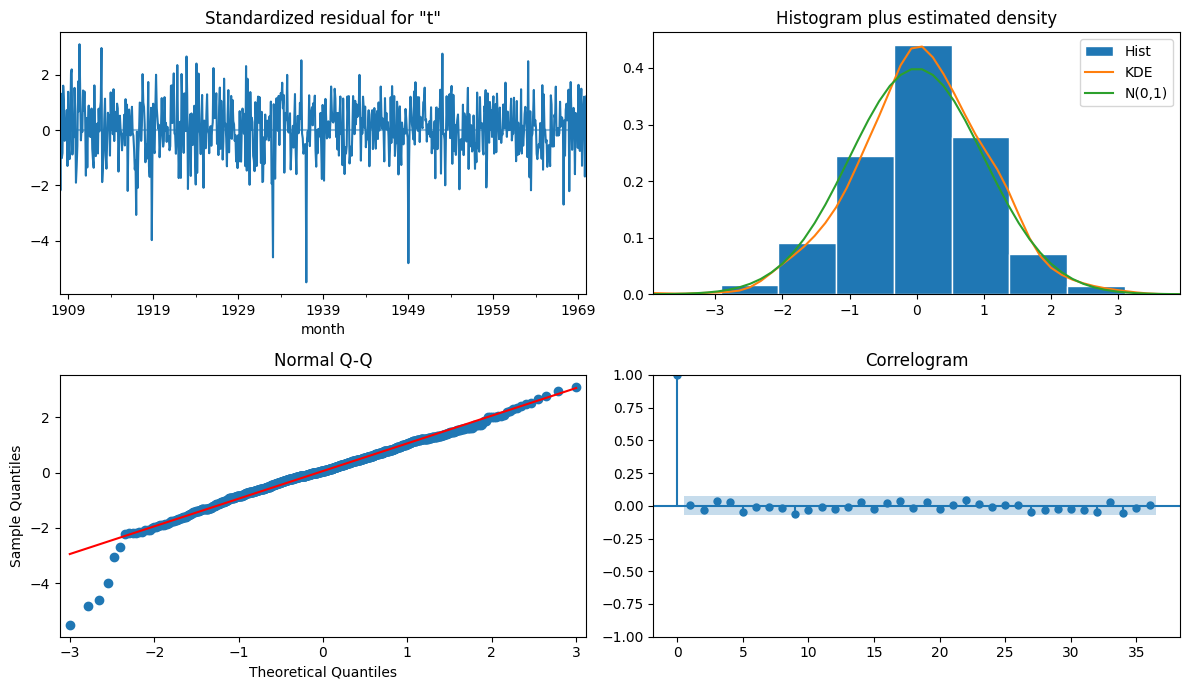

residual autocorrelation at lag 12: -0.02


,lb_stat,lb_pvalue
12,8.240435,0.510110
24,14.495254,0.847401
36,24.381445,0.861345


In [12]:
sarima_fit.plot_diagnostics(figsize=(12, 7), lags=36)
plt.tight_layout(); plt.show()

sarima_resid = sarima_fit.resid.iloc[sarima_fit.loglikelihood_burn:]
print(f"residual autocorrelation at lag 12: {acf(sarima_resid, nlags=12)[12]:.2f}")
acorr_ljungbox(sarima_resid, lags=[12, 24, 36], model_df=3)

The lag-12 spike is gone (residual autocorrelation $-0.02$), and the Ljung-Box test no longer rejects at any $h$. The histogram and QQ plot still show heavy tails: the seasonal heteroskedasticity of Chapter 11 is still there, since SARIMA also assumes a constant $\sigma^2$.

Now the forecast of the three test years. `SARIMAX` forecasts on the original scale; the seasonal difference is undone internally.

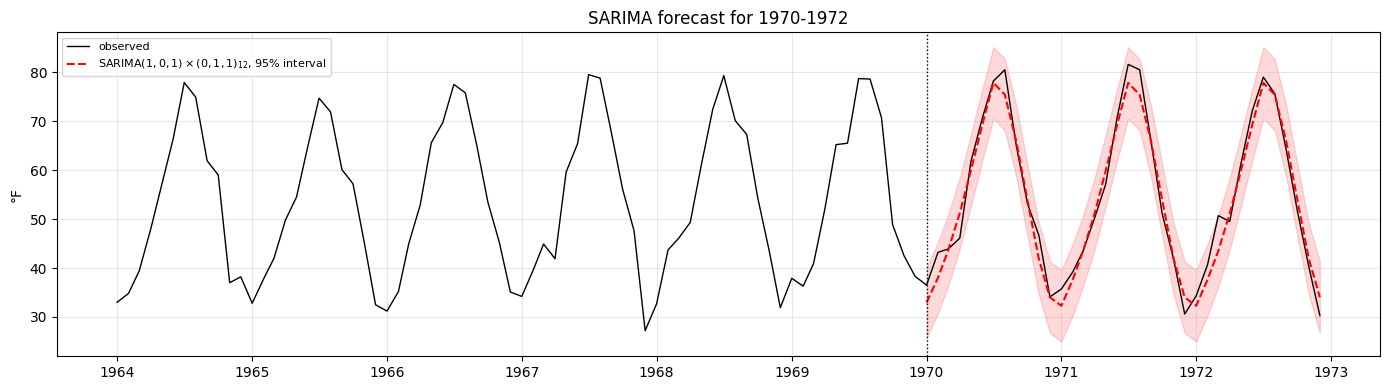

In [13]:
_, ax = plt.subplots(figsize=(14, 4))
ax.plot(temp["1964-01-01":], color="black", lw=1, label="observed")
sarima_pred = forecast_with_interval(ax, sarima_fit, len(temp_test), temp_test.index,
                                     label=r"SARIMA$(1,0,1)\times(0,1,1)_{12}$, 95% interval")
ax.axvline(temp_test.index[0], color="black", ls=":", lw=1)
ax.set(title="SARIMA forecast for 1970-1972", ylabel="°F"); ax.grid(alpha=0.3)
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

We compare with the forecasts of Chapter 11, recomputed here: the seasonal naive benchmark, the monthly means, and the monthly means plus an ARMA(1,1) forecast of the anomalies.

In [14]:
monthly_means = temp_train.groupby(temp_train.index.month).mean()
means_test = monthly_means.loc[temp_test.index.month].to_numpy()
anomalies = temp_train - monthly_means.loc[temp_train.index.month].to_numpy()
anom_fit = ARIMA(anomalies, order=(1, 0, 1)).fit()

score_table(temp_test, {
    "seasonal naive":                  np.tile(temp_train.iloc[-12:].to_numpy(), 3),
    "monthly means":                   means_test,
    "monthly means + ARMA(1,1)":       means_test + anom_fit.forecast(len(temp_test)).to_numpy(),
    "SARIMA(1,0,1)(0,1,1)_12":         sarima_pred,
})

                                     MSE, all 36 steps    MSE, first 3 steps
seasonal naive                                   21.28                 19.52
monthly means                                     8.82                 16.64
monthly means + ARMA(1,1)                         8.57                 13.42
SARIMA(1,0,1)(0,1,1)_12                           8.59                 13.19


SARIMA and "monthly means + ARMA(1,1)" are practically the same forecast (MSE 8.59 and 8.57, and 13.19 and 13.42 over the first three months). Both beat the monthly means alone and are more than twice as accurate as seasonal naive. That is what $\hat\Theta_1 \approx -0.98$ and the matching ARMA coefficients predicted: SARIMA has rediscovered "fixed seasonal pattern plus ARMA(1,1) anomalies" on its own, starting from the seasonal difference that failed in Chapter 11.

The advantage of SARIMA is that we did not have to know the answer in advance: the same model handles a seasonal pattern that does change over time ($\Theta_1$ further from $-1$), and it does the bookkeeping for us.

---

# Selecting the best model

By now it should be clear that identifying the best SARIMA model is difficult. It requires careful analysis, trial and error, and some experience. The following cheatsheet summarizes the rules of thumb.

**Cheatsheet: reading the ACF**

| ACF shape | Indicated model |
|---|---|
| Exponential, decaying to zero | AR model. Use the PACF to identify the order. |
| Alternating positive and negative, decaying to zero | AR model. Use the PACF to identify the order. |
| One or more spikes, the rest essentially zero | MA model, order identified by where the plot becomes zero. |
| Decay, starting after a few lags | Mixed AR and MA (ARMA) model. |
| All zero or close to zero | The data are essentially random. |
| High values at fixed intervals | Include a seasonal AR term. |
| No decay to zero | The series is not stationary. |

There are two ways to go beyond rules of thumb: let an automatic procedure choose, or fit a set of candidates and compare them ourselves.

## AutoARIMA

An alternative to manual model selection is to use automated procedures. The best known is `auto_arima` from the `pmdarima` package, a Python version of R's `auto.arima`. You specify the maximum range of values to try, and it searches for the best configuration among them, by default with a **stepwise** search that starts from a few simple models and moves to neighbouring orders as long as the AIC improves. `pmdarima` is not installed in the course environment, so we show the call without running it. See the [documentation](https://alkaline-ml.com/pmdarima/modules/generated/pmdarima.arima.auto_arima.html) for the complete list of options.

```python
import pmdarima as pm

model = pm.auto_arima(train,
                      start_p=0, start_q=0, max_p=2, max_q=2,   # range of p and q
                      d=None, test="adf",                       # choose d with the ADF test
                      seasonal=True, m=12,                      # seasonal model with period 12
                      start_P=0, start_Q=0, max_P=2, max_Q=2,   # range of P and Q
                      D=1,                                      # one seasonal difference
                      stepwise=True,                            # stepwise search, not the full grid
                      trace=True,                               # print every model it fits
                      error_action="ignore", suppress_warnings=True)
print(model.summary())
forecast = model.predict(n_periods=len(test))
```

> **Caution.** Look at the trace before trusting the answer. In the handbook's run of this call on the temperatures (training on the first 750 months), every candidate with a seasonal MA term, seven of the 31 models tried, came back with `AIC=inf`: the fit failed, and `error_action="ignore"` silently skipped it. `auto_arima` then returned SARIMA$(1,0,1)\times(2,1,0)_{12}$, which approximates the missing seasonal MA term with two seasonal AR lags. The cell below fits both models on those 750 months.

In [15]:
first_750 = temp.iloc[:750]
for order, seasonal_order in [((1, 0, 1), (2, 1, 0, 12)), ((1, 0, 1), (0, 1, 1, 12))]:
    fit = SARIMAX(first_750, order=order, seasonal_order=seasonal_order).fit(disp=False)
    print(f"SARIMA{order}x{seasonal_order}:  AIC = {fit.aic:.1f}")

SARIMA(1, 0, 1)x(2, 1, 0, 12):  AIC = 4226.5


SARIMA(1, 0, 1)x(0, 1, 1, 12):  AIC = 4051.8


The model that the automatic search could not fit is better by more than 170 AIC points.

AutoARIMA is very convenient, but like all automated procedures it comes with drawbacks.

1. It can be **computationally expensive**, especially for large datasets and wide ranges of orders.
2. It lacks the qualitative insight a human brings: knowledge of business cycles, external factors, or anomalies in the data.
3. Its **defaults** are not optimal for all data. The ranges of values to explore must be adjusted each time, which can become almost as tricky as manual selection.
4. It needs a sufficiently **long series** to identify the patterns and the seasonality reliably.
5. It selects by **statistical criteria** such as AIC or BIC, which do not always agree with practical performance measures such as the MSE of the forecasts.

## Grid search

Selecting the best SARIMA model is as much an art as a science, and involves iteration and refinement. A common approach is to choose a set of candidate values for $(p, d, q) \times (P, D, Q)_s$ and fit a model for every combination. For each fitted model we

- analyze the residuals, with the plots and tests of Chapter 11;
- evaluate its **prediction performance**;
- evaluate its **complexity**.

### Prediction performance

We use the MSE and the MAPE, where $Y_i$ is an observation and $\hat Y_i$ its prediction.

**Mean squared error**, $\mathrm{MSE} = \frac{1}{n}\sum_{i=1}^{n}(Y_i - \hat Y_i)^2$. A lower MSE means a better fit, with large errors weighted most.

**Mean absolute percentage error**, $\mathrm{MAPE} = \frac{100\%}{n}\sum_{i=1}^{n}\left|\frac{Y_i - \hat Y_i}{Y_i}\right|$. It expresses errors as a percentage of the observations, which makes it easy to read, allows comparisons between series on different scales (dollars vs units sold), and is relevant when we care about the relative rather than the absolute size of the errors.

> **Attention.** A percentage error needs a **meaningful zero**. Temperatures in °F do not have one: 0 °F is an arbitrary point, and the same forecasts would have a different MAPE in °C. Recall also from Chapter 1 that MAPE explodes near zero. We report it here, but rank by MSE when the two disagree.

### Model complexity

We use the AIC and BIC of Chapter 11, $\mathrm{AIC} = -2\ln\hat L + 2k$ and $\mathrm{BIC} = -2\ln\hat L + k\ln n$, where $k$ is the number of parameters, $n$ the number of observations and $\hat L$ the maximized likelihood. Both trade goodness of fit against complexity; BIC penalizes extra parameters more, and prefers simpler models as $n$ grows.

> **Attention.** AIC and BIC compare models fitted to the **same data**. A model with $d = 1$ or $D = 1$ is fitted to the differenced series: `statsmodels` leaves the first $d + Ds$ observations out of its likelihood (`loglikelihood_burn`), and the rest are differences, not levels. So **compare AIC and BIC only between models with the same $d$ and $D$**, and use out-of-sample errors to choose the differencing.

### Restricting the search with EDA

An exhaustive grid search can be very expensive, especially on limited hardware. An exploratory data analysis can cut the number of candidates considerably.

#### Candidates for differencing

We start with all combinations of seasonal and regular differencing. We already know that the main seasonality is $s = 12$. Should the regular or the seasonal difference come first? Mathematically the order does not matter (Chapter 10), but it helps the analysis: if the seasonal pattern is dominant, as here, start with **seasonal differencing**, which removes the seasonality before addressing any trend; if the trend dominates, start with the regular difference.

In [16]:
def differencing(series, s, D_max=2, d_max=2):
    "All combinations of D <= D_max seasonal and then d <= d_max regular differences of a series."
    out = {}
    for D in range(D_max + 1):
        seasonal = series.copy()
        for _ in range(D):
            seasonal = seasonal.diff(s)
        for d in range(d_max + 1):
            diffed = seasonal.copy()
            for _ in range(d):
                diffed = diffed.diff()
            out[f"d{d}_D{D}"] = diffed
    return pd.DataFrame(out)


diff_series = differencing(temp_train, s=12)
diff_series.iloc[22:28].round(1)        # the first rows are NaN where differences are undefined

,d0_D0,d1_D0,d2_D0,d0_D1,d1_D1,d2_D1,d0_D2,d1_D2,d2_D2
month,,,,,,,,,
1908-11-01,41.4,-4.1,15.3,3.6,4.3,3.6,NaN,NaN,NaN
1908-12-01,31.6,-9.8,-5.7,-6.0,-9.6,-13.9,NaN,NaN,NaN
1909-01-01,40.0,8.4,18.2,4.4,10.4,20.0,2.1,NaN,NaN
1909-02-01,38.4,-1.6,-10.0,3.2,-1.2,-11.6,14.0,11.9,NaN
1909-03-01,40.8,2.4,4.0,-7.3,-10.5,-9.3,-12.4,-26.4,-38.3
1909-04-01,52.8,12.0,9.6,2.8,10.1,20.6,7.8,20.2,46.6


Next, a summary of the ADF test for each series, plus its standard deviation.

In [17]:
def adf_summary(diff_series):
    "ADF test results and standard deviation of every column of a DataFrame."
    rows = {}
    for name, series in diff_series.items():
        stat, pvalue, lags, nobs, crit, _ = adfuller(series.dropna())
        rows[name] = {"ADF statistic": stat, "p-value": pvalue, "lags used": lags, "observations": nobs,
                      "critical value (5%)": crit["5%"], "std": series.std()}
    return pd.DataFrame(rows).T


summary = adf_summary(diff_series)
summary.round(3)

,ADF statistic,p-value,lags used,observations,critical value (5%),std
d0_D0,-7.697,0.0,17.0,738.0,-2.865,15.816
d1_D0,-10.644,0.0,20.0,734.0,-2.865,9.465
d2_D0,-15.479,0.0,17.0,736.0,-2.865,9.321
d0_D1,-8.357,0.0,15.0,728.0,-2.866,5.297
d1_D1,-11.549,0.0,20.0,722.0,-2.866,6.717
d2_D1,-13.877,0.0,20.0,721.0,-2.866,11.348
d0_D2,-9.001,0.0,15.0,716.0,-2.866,9.200
d1_D2,-11.791,0.0,20.0,710.0,-2.866,11.564
d2_D2,-14.710,0.0,20.0,709.0,-2.866,19.586


**Filtering out nonstationary candidates.** The plan was to keep only the series that pass the ADF test. Here all nine pass, including the undifferenced temperatures, so the filter removes nothing. This is the lesson of the sinusoid in Chapter 11: the temperatures have no unit root, so the ADF test cannot tell us whether to difference away the seasonality.

The **standard deviation** is more informative. A difference that removes structure lowers the variance; a difference that is not needed raises it, because differencing white noise doubles its variance. The seasonal difference alone, `d0_D1`, has the smallest spread (5.3 °F, against 15.8 for the raw data). Adding a regular difference (`d1_D1`, 6.7) or a second seasonal one (`d0_D2`, 9.2) increases it: **over-differencing**. We plot all nine series.

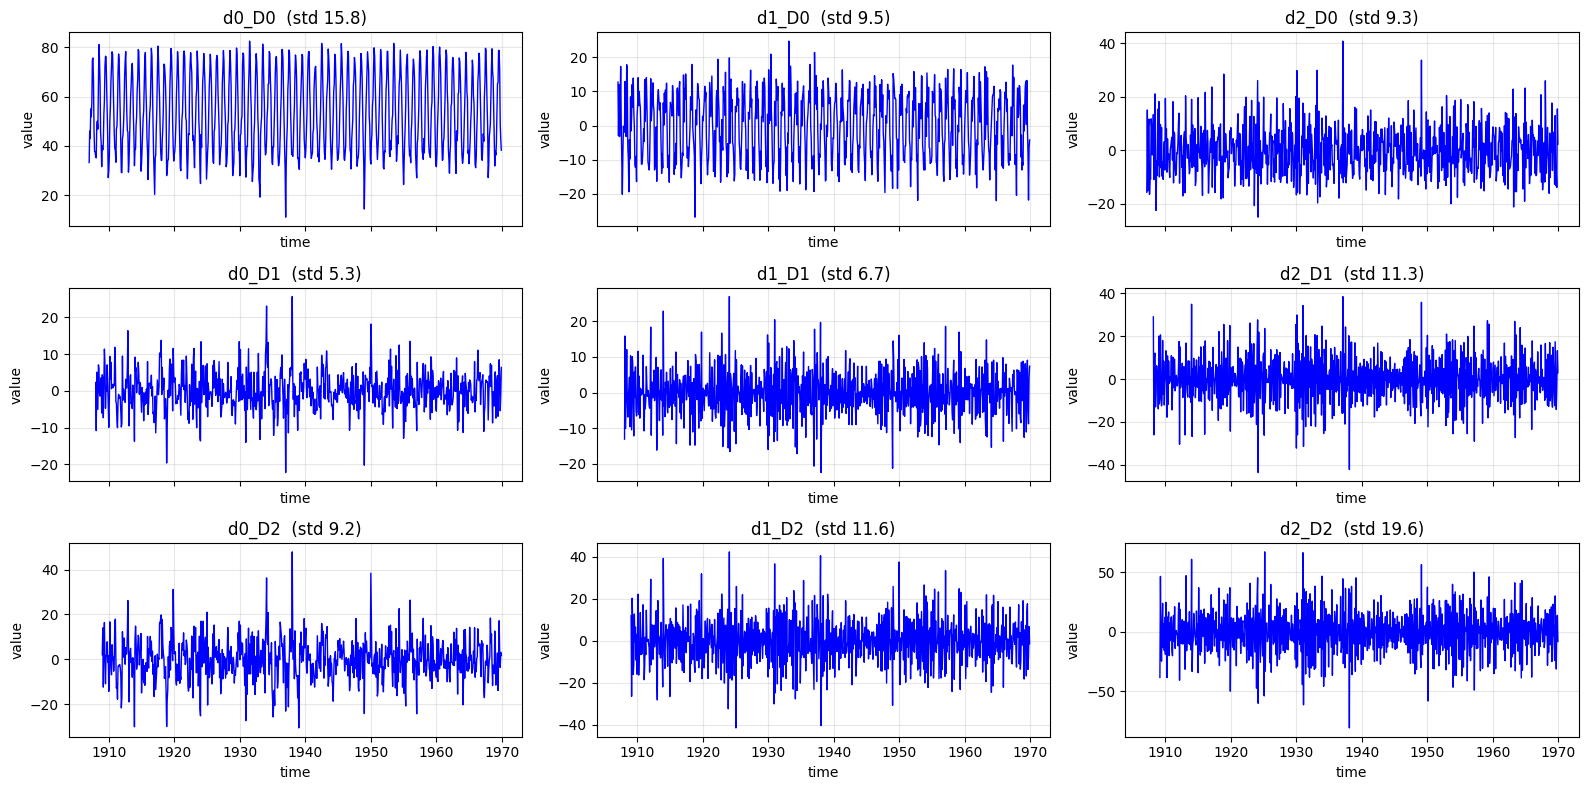

In [18]:
fig, axes = plt.subplots(3, 3, figsize=(16, 8), sharex=True)
for ax, name in zip(axes.flatten(), diff_series.columns):
    run_sequence_plot(diff_series[name], title=f"{name}  (std {summary.loc[name, 'std']:.1f})", ax=ax)
plt.tight_layout(); plt.show()

The plots agree with the numbers. Without a seasonal difference (top row) the seasonal oscillation is still visible, even after two regular differences. After one seasonal difference (`d0_D1`) the series looks like noise around zero; every further difference keeps it noise-like but makes it larger, up to a standard deviation of 19.6 for `d2_D2`. We keep $D = 1$, since the seasonal pattern must go and $D = 2$ over-differences, and $d \in \{0, 1\}$, keeping $d = 1$ in the grid to let the data confirm that it is not needed.

#### Candidates for $p$, $q$, $P$, $Q$

To extract candidate orders for the AR and MA parts, both regular and seasonal, we use the ACF and PACF as **numbers** instead of plots: `acf` and `pacf` from `statsmodels.tsa.stattools`. With `alpha=0.05` they also return a 95% confidence interval for each value. How does that relate to the band in `plot_acf`?

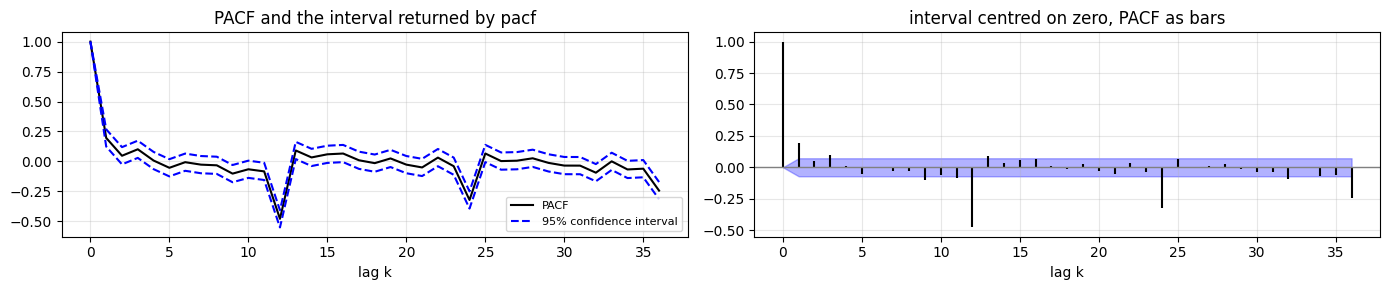

In [19]:
x = diff_series["d0_D1"].dropna()
PACF, PACF_ci = pacf(x, nlags=36, alpha=0.05)

fig, axes = plt.subplots(1, 2, figsize=(14, 3))
axes[0].plot(PACF, color="black", label="PACF")
axes[0].plot(PACF_ci[:, 0], color="blue", ls="--", label="95% confidence interval")
axes[0].plot(PACF_ci[:, 1], color="blue", ls="--")
axes[0].set(title="PACF and the interval returned by pacf", xlabel="lag k")

# subtract the PACF from the interval to centre it on zero: the band of plot_pacf
lags = np.arange(len(PACF))
axes[1].fill_between(lags, PACF_ci[:, 0] - PACF, PACF_ci[:, 1] - PACF, color="blue", alpha=0.3)
axes[1].vlines(lags, 0, PACF, color="black")
axes[1].axhline(0, color="gray", lw=1)
axes[1].set(title="interval centred on zero, PACF as bars", xlabel="lag k")
for ax in axes:
    ax.grid(alpha=0.3)
axes[0].legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

The interval returned by `pacf` is centred on each estimate. Subtracting the estimate centres it on zero, and gives the shaded band of `plot_pacf` (right panel). A value is **significant** when it lies outside that band. The function below collects the significant lags of a series, with the absolute value of the correlation at each.

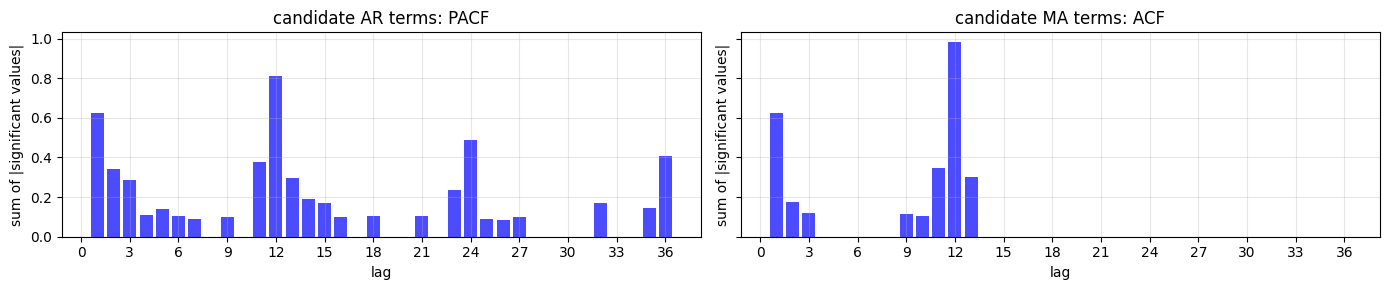

In [20]:
def significant_spikes(series, function, nlags=36):
    "Lags (>= 1) where the ACF or PACF of a series lies outside its 95% band, with |value|."
    values, ci = function(series.dropna(), nlags=nlags, alpha=0.05)
    half_width = ci[:, 1] - values                     # the band, centred on zero
    lags = np.arange(len(values))
    keep = (np.abs(values) > half_width) & (lags > 0)
    return pd.Series(np.abs(values[keep]), index=lags[keep])


candidates = ["d0_D1", "d1_D1"]                        # the series kept by the EDA above
spikes_pacf = pd.concat([significant_spikes(diff_series[c], pacf) for c in candidates], axis=1).sum(axis=1)
spikes_acf = pd.concat([significant_spikes(diff_series[c], acf) for c in candidates], axis=1).sum(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(14, 3), sharey=True)
for ax, spikes, name in [(axes[0], spikes_pacf, "candidate AR terms: PACF"),
                         (axes[1], spikes_acf, "candidate MA terms: ACF")]:
    spikes = spikes.reindex(range(1, 37), fill_value=0)
    ax.bar(spikes.index, spikes, color="blue", alpha=0.7)
    ax.set(title=name, xlabel="lag", ylabel="sum of |significant values|", xticks=range(0, 37, 3))
    ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

The bars sum the significant values over the two candidate series, so a lag scores high if it is strongly significant in both.

- **Seasonal lags.** Lag 12 dominates both charts. In the PACF, lags 24 and 36 follow; in the ACF they are absent. This is again the seasonal MA(1) signature: $Q \in \{0, 1\}$, and we also try $P \in \{0, 1\}$.
- **Short lags.** Lag 1 is the largest non-seasonal spike in both charts, followed by lags 2 and 3. Lags 11 and 13 are interactions between the short lags and lag 12, as in the SARIMA$(0,0,1)\times(0,0,1)_{12}$ example. So $p \in \{1, 2, 3\}$ and $q \in \{1, 2\}$.

#### The grid of values to search

In [21]:
p = [1, 2, 3]
d = [0, 1]
q = [1, 2]
P = [0, 1]
D = [1]
Q = [0, 1]
s = [12]

# all combinations of the candidate values
pdq = list(product(p, d, q))
PDQs = list(product(P, D, Q, s))
print(f"Number of combinations: {len(pdq) * len(PDQs)}")

Number of combinations: 48


A naive search over $p, q, P, Q \in \{0, \dots, 3\}$ and $d, D \in \{0, 1, 2\}$ would fit $4^4 \cdot 3^2 = 2{,}304$ models; the EDA has cut this to 48.

#### Training the models

The function below fits every configuration and records the MSE and MAPE of the in-sample one-step-ahead predictions, the AIC and the BIC.

> **Attention.** The in-sample errors must be computed on the **same observations** for every model. A model with $D = 1$ has not seen a full year during its first 12 predictions, which are dominated by the initialization and are far off. Including them would penalize these models for their start-up and not for their fit. We skip the first two years for every model. To show how much it matters, we also record the MSE computed from the second observation on, `MSE from t=1`.

In [22]:
def sarima_grid(endog, orders, seasonal_orders, skip=24):
    "Fit SARIMAX for every combination; in-sample MSE/MAPE (after `skip` points), AIC and BIC."
    rows = []
    for order in orders:
        for seasonal_order in seasonal_orders:
            try:
                fit = SARIMAX(endog=endog, order=order, seasonal_order=seasonal_order).fit(disp=False)
            except Exception:              # a failed fit is skipped, but we count how many
                rows.append({"order": order, "seasonal_order": seasonal_order, "failed": True})
                continue
            predict = fit.predict()        # in-sample one-step-ahead predictions
            rows.append({"order": order, "seasonal_order": seasonal_order, "failed": False,
                         "MAPE": mape(endog[skip:], predict[skip:]),
                         "MSE": mse(endog[skip:], predict[skip:]),
                         "MSE from t=1": mse(endog[1:], predict[1:]),
                         "AIC": fit.aic, "BIC": fit.bic})
    return pd.DataFrame(rows)


start = time.perf_counter()
model_info = sarima_grid(temp_train, pdq, PDQs)
print(f"time required: {time.perf_counter() - start:.0f} s,  failed fits: {model_info['failed'].sum()}")

model_info = model_info[~model_info["failed"]].drop(columns="failed")
model_info["d"] = model_info["order"].map(lambda o: o[1])

time required: 115 s,  failed fits: 0


First, the effect of the start-up period: the best MSE in each group of models with the same $d$, computed both ways.

In [23]:
model_info.groupby("d")[["MSE", "MSE from t=1"]].min().round(2)

,MSE,MSE from t=1
d,,
0,13.97,58.62
1,14.22,16.52


From the second observation on, the $d = 0$ models look three and a half times worse than the $d = 1$ models (an MSE of 58.6 against 16.5). On the common span after two years they are slightly **better** (14.0 against 14.2). The whole gap comes from the first 12 predictions. During its first year a model with $d = 0$ and $D = 1$ has no earlier January, February, ... to compare with, and predicts 0 °F; a model with $d = 1$ can at least repeat the previous month. A careless comparison would have selected the over-differenced models.

#### Analyzing the results

The 10 best models according to each measure: in-sample performance (MSE, MAPE) and complexity (AIC, BIC).

In [24]:
show = ["order", "seasonal_order", "MSE", "MAPE", "AIC", "BIC"]
least_MSE = model_info.nsmallest(10, "MSE")
least_MSE[show].round(3)

,order,seasonal_order,MSE,MAPE,AIC,BIC
39,"(3, 0, 2)","(1, 1, 1, 12)",13.967,6.464,4088.950,4125.846
35,"(3, 0, 1)","(1, 1, 1, 12)",13.977,6.469,4087.910,4120.195
37,"(3, 0, 2)","(0, 1, 1, 12)",13.978,6.477,4087.726,4120.010
33,"(3, 0, 1)","(0, 1, 1, 12)",13.989,6.484,4086.741,4114.413
23,"(2, 0, 2)","(1, 1, 1, 12)",13.993,6.471,4089.263,4121.547
7,"(1, 0, 2)","(1, 1, 1, 12)",13.999,6.472,4087.729,4115.401
21,"(2, 0, 2)","(0, 1, 1, 12)",14.006,6.483,4088.211,4115.883
19,"(2, 0, 1)","(1, 1, 1, 12)",14.009,6.475,4087.999,4115.671
3,"(1, 0, 1)","(1, 1, 1, 12)",14.009,6.474,4086.105,4109.165
5,"(1, 0, 2)","(0, 1, 1, 12)",14.013,6.483,4086.725,4109.785


In [25]:
least_MAPE = model_info.nsmallest(10, "MAPE")
least_MAPE[show].round(3)

,order,seasonal_order,MSE,MAPE,AIC,BIC
39,"(3, 0, 2)","(1, 1, 1, 12)",13.967,6.464,4088.950,4125.846
35,"(3, 0, 1)","(1, 1, 1, 12)",13.977,6.469,4087.910,4120.195
23,"(2, 0, 2)","(1, 1, 1, 12)",13.993,6.471,4089.263,4121.547
7,"(1, 0, 2)","(1, 1, 1, 12)",13.999,6.472,4087.729,4115.401
3,"(1, 0, 1)","(1, 1, 1, 12)",14.009,6.474,4086.105,4109.165
19,"(2, 0, 1)","(1, 1, 1, 12)",14.009,6.475,4087.999,4115.671
37,"(3, 0, 2)","(0, 1, 1, 12)",13.978,6.477,4087.726,4120.010
5,"(1, 0, 2)","(0, 1, 1, 12)",14.013,6.483,4086.725,4109.785
17,"(2, 0, 1)","(0, 1, 1, 12)",14.016,6.483,4086.825,4109.885
21,"(2, 0, 2)","(0, 1, 1, 12)",14.006,6.483,4088.211,4115.883


In [26]:
least_AIC = model_info.nsmallest(10, "AIC")
least_AIC[show].round(3)

,order,seasonal_order,MSE,MAPE,AIC,BIC
1,"(1, 0, 1)","(0, 1, 1, 12)",14.023,6.483,4085.100,4103.548
3,"(1, 0, 1)","(1, 1, 1, 12)",14.009,6.474,4086.105,4109.165
5,"(1, 0, 2)","(0, 1, 1, 12)",14.013,6.483,4086.725,4109.785
33,"(3, 0, 1)","(0, 1, 1, 12)",13.989,6.484,4086.741,4114.413
17,"(2, 0, 1)","(0, 1, 1, 12)",14.016,6.483,4086.825,4109.885
37,"(3, 0, 2)","(0, 1, 1, 12)",13.978,6.477,4087.726,4120.010
7,"(1, 0, 2)","(1, 1, 1, 12)",13.999,6.472,4087.729,4115.401
35,"(3, 0, 1)","(1, 1, 1, 12)",13.977,6.469,4087.910,4120.195
19,"(2, 0, 1)","(1, 1, 1, 12)",14.009,6.475,4087.999,4115.671
21,"(2, 0, 2)","(0, 1, 1, 12)",14.006,6.483,4088.211,4115.883


In [27]:
least_BIC = model_info.nsmallest(10, "BIC")
least_BIC[show].round(3)

,order,seasonal_order,MSE,MAPE,AIC,BIC
1,"(1, 0, 1)","(0, 1, 1, 12)",14.023,6.483,4085.100,4103.548
3,"(1, 0, 1)","(1, 1, 1, 12)",14.009,6.474,4086.105,4109.165
5,"(1, 0, 2)","(0, 1, 1, 12)",14.013,6.483,4086.725,4109.785
17,"(2, 0, 1)","(0, 1, 1, 12)",14.016,6.483,4086.825,4109.885
9,"(1, 1, 1)","(0, 1, 1, 12)",14.283,6.589,4093.128,4111.571
33,"(3, 0, 1)","(0, 1, 1, 12)",13.989,6.484,4086.741,4114.413
7,"(1, 0, 2)","(1, 1, 1, 12)",13.999,6.472,4087.729,4115.401
13,"(1, 1, 2)","(0, 1, 1, 12)",14.250,6.568,4092.472,4115.526
19,"(2, 0, 1)","(1, 1, 1, 12)",14.009,6.475,4087.999,4115.671
21,"(2, 0, 2)","(0, 1, 1, 12)",14.006,6.483,4088.211,4115.883


We can check whether the four groups overlap with Python's `set` operations on the row labels.

In [28]:
print("MSE  and MAPE:", sorted(set(least_MSE.index) & set(least_MAPE.index)))
print("AIC  and BIC: ", sorted(set(least_AIC.index) & set(least_BIC.index)))
print("MSE  and AIC: ", sorted(set(least_MSE.index) & set(least_AIC.index)))

MSE  and MAPE: [3, 5, 7, 19, 21, 23, 35, 37, 39]
AIC  and BIC:  [1, 3, 5, 7, 17, 19, 21, 33]
MSE  and AIC:  [3, 5, 7, 19, 21, 33, 35, 37]


The best model according to each measure:

In [29]:
best_models = pd.concat([model_info.nsmallest(1, metric).assign(selected_by=metric)
                         for metric in ["MSE", "MAPE", "AIC", "BIC"]])
best_models[["selected_by"] + show].round(3)

,selected_by,order,seasonal_order,MSE,MAPE,AIC,BIC
39,MSE,"(3, 0, 2)","(1, 1, 1, 12)",13.967,6.464,4088.95,4125.846
39,MAPE,"(3, 0, 2)","(1, 1, 1, 12)",13.967,6.464,4088.95,4125.846
1,AIC,"(1, 0, 1)","(0, 1, 1, 12)",14.023,6.483,4085.10,4103.548
1,BIC,"(1, 0, 1)","(0, 1, 1, 12)",14.023,6.483,4085.10,4103.548


Reading the tables:

- Once the start-up period is excluded, the four measures largely agree. The top-10 lists by MSE and MAPE share 9 models, those by AIC and BIC share 8, and those by MSE and AIC share 8. Every model in the MSE, MAPE and AIC lists has $d = 0$. (The BIC list contains two $d = 1$ models, but their BIC is not comparable with that of the $d = 0$ models.)
- The differences are small. The in-sample MSE of the ten best models ranges from 13.97 to 14.02, less than 0.5%, and the ten best AIC values lie within 3.2 points.
- In-sample MSE and MAPE prefer the largest model of the grid, SARIMA$(3,0,2)\times(1,1,1)_{12}$, with 7 coefficients: in-sample errors can only go down as parameters are added. AIC and BIC charge for the extra parameters and pick SARIMA$(1,0,1)\times(0,1,1)_{12}$, with 3: the model we identified by hand from the correlograms.

#### Performance on the test set

Finally, we refit the selected models, forecast the three test years, and compute MSE and MAPE on the test set. We add the monthly-means forecast of Chapter 11 as the benchmark to beat.

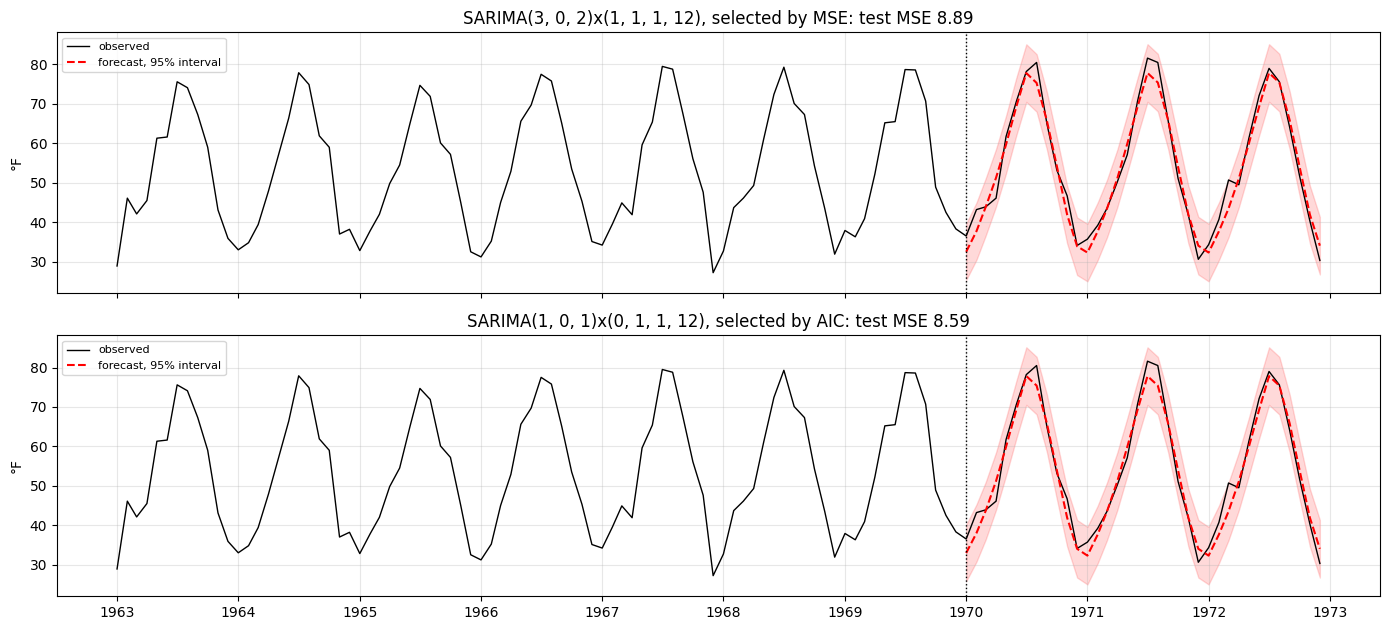

,selected by,test MSE,test MAPE (%)
"SARIMA(3, 0, 2)x(1, 1, 1, 12)",MSE,8.89,4.83
"SARIMA(1, 0, 1)x(0, 1, 1, 12)",AIC,8.59,4.73
monthly means (benchmark),-,8.82,4.81


In [30]:
unique_best = best_models.drop_duplicates(subset=["order", "seasonal_order"])

fig, axes = plt.subplots(len(unique_best), 1, figsize=(14, 3.2 * len(unique_best)), sharex=True, squeeze=False)
results = {}
for ax, (_, row) in zip(axes[:, 0], unique_best.iterrows()):
    fit = SARIMAX(temp_train, order=row["order"], seasonal_order=row["seasonal_order"]).fit(disp=False)
    ax.plot(temp["1963-01-01":], color="black", lw=1, label="observed")
    pred = forecast_with_interval(ax, fit, len(temp_test), temp_test.index, label="forecast, 95% interval")
    name = f"SARIMA{row['order']}x{row['seasonal_order']}"
    results[name] = {"selected by": row["selected_by"], "test MSE": mse(temp_test, pred),
                     "test MAPE (%)": mape(temp_test, pred)}
    ax.axvline(temp_test.index[0], color="black", ls=":", lw=1)
    ax.set(title=f"{name}, selected by {row['selected_by']}: test MSE {results[name]['test MSE']:.2f}",
           ylabel="°F")
    ax.grid(alpha=0.3); ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

results["monthly means (benchmark)"] = {"selected by": "-", "test MSE": mse(temp_test, means_test),
                                        "test MAPE (%)": mape(temp_test, means_test)}
pd.DataFrame(results).T.astype({"test MSE": float, "test MAPE (%)": float}).round(2)

- The model chosen by AIC and BIC has the lowest test errors (MSE 8.59, MAPE 4.73%). The large model chosen by in-sample MSE does slightly worse (8.89), even worse than the monthly-means benchmark (8.82): its four extra parameters fitted noise in the training data.
- All three are within 0.3 of each other, a difference that a single 36-month test period cannot resolve (Chapter 11). The two firm conclusions are that any model that captures the fixed seasonal pattern is more than twice as accurate as seasonal naive, and that the extra parameters do not pay.

---

# Summary

**ARIMA($p, d, q$)**: $\ \phi(B)\,(1 - B)^d\,x_t = c + \theta(B)\,\varepsilon_t$.

- $d$ differences make the series stationary inside the model, and the forecasts come back on the original scale. Random walk = ARIMA(0,1,0), SES = ARIMA(0,1,1) with $\alpha = 1 + \theta_1$, ARMA = ARIMA($p$, 0, $q$).
- With $d \ge 1$, a constant is a **trend**: a drift for $d = 1$ (`trend="t"`), a quadratic for $d = 2$ (`trend=[0, 0, 1]`). `statsmodels` leaves it out by default.
- **Over-differencing** shows up as forecasts that do not revert to the mean, intervals that grow without bound, a larger variance of the differenced series, and an MA coefficient near $-1$ (an MA unit root).

**SARIMA$(p, d, q) \times (P, D, Q)_s$**: $\ \Phi(B^s)\,\phi(B)\,(1 - B^s)^D (1 - B)^d\,x_t = c + \Theta(B^s)\,\theta(B)\,\varepsilon_t$.

- $s$ from the ACF, the subseries plot or the FFT; $D$ usually 0 or 1; $P$ and $Q$ from the PACF and ACF at the seasonal lags $s, 2s, \dots$, with the AR and MA rules of Chapters 9 and 10.
- A seasonal MA coefficient $\Theta_1 \approx -1$ cancels the seasonal difference: the seasonal pattern is (nearly) fixed, and SARIMA becomes "monthly means + ARMA".

**Model selection**

| Step | Tool | Watch out for |
|---|---|---|
| Differencing $d$, $D$ | ADF, plots, the variance of the differenced series | ADF cannot see seasonality; extra differences raise the variance |
| Orders $p, q, P, Q$ | significant ACF/PACF spikes, the cheatsheet | short lags for $p, q$, seasonal lags for $P, Q$ |
| Ranking candidates | in-sample MSE/MAPE, AIC, BIC | same observations for every model; AIC/BIC only for the same $d$ and $D$; MAPE needs a meaningful zero |
| Final choice | errors on held-out data, against a simple benchmark | one test period is noisy (Chapter 11) |
| Automatic search | `auto_arima` | read the trace: failed fits are skipped silently |

**What we learned on the temperatures**

1. The seasonal ACF/PACF pattern pointed to a seasonal MA(1), and SARIMA$(1,0,1)\times(0,1,1)_{12}$ removed the lag-12 correlation that no ARMA model of Chapter 11 could.
2. Its seasonal MA coefficient, $-0.98$, showed that the seasonality is almost deterministic. SARIMA then forecasts like "monthly means + ARMA(1,1)" (test MSE 8.59 vs 8.57), more than twice as accurate as seasonal naive.
3. The grid search confirmed $d = 0$ once the models were compared fairly, and AIC and BIC picked the hand-identified model, which also forecast best. It also showed how easily a start-up artifact, or an automatic search that skips failed fits, can pick the wrong model.